# WAR Dependency Simulator

## Write After Read (WAR)

WAR (Write After Read) adalah dependency yang terjadi ketika
sebuah instruksi berikutnya menulis ke register yang sebelumnya
dibaca oleh instruksi sebelumnya.

Contoh:

I1: R1 = R2 + R3
I2: R2 = R4 + R5

I1 membaca R2, sedangkan I2 menulis R2.
Maka terdapat WAR dependency:

I1 → I2

In [1]:
import re
import networkx as nx
import matplotlib.pyplot as plt

print("Library berhasil diimport!")

Library berhasil diimport!


In [2]:
# ==========================================
# INPUT INSTRUKSI
# ==========================================

instructions = [
    "R1 = R2 + R3",
    "R2 = R4 + R5",
    "R6 = R1 + R7",
    "R3 = R8 + R9"
]

print("Daftar Instruksi:")
for i, instruction in enumerate(instructions, start=1):
    print(f"I{i}: {instruction}")

Daftar Instruksi:
I1: R1 = R2 + R3
I2: R2 = R4 + R5
I3: R6 = R1 + R7
I4: R3 = R8 + R9


In [3]:
# ==========================================
# IDENTIFIKASI REGISTER READ DAN WRITE
# ==========================================

def get_registers(instruction):
    """
    Mengambil semua register dari sebuah instruksi.
    """
    return re.findall(r'R\d+', instruction)


def get_read_registers(instruction):
    """
    Mengambil register yang dibaca.
    Register pertama dianggap sebagai WRITE,
    sedangkan register berikutnya dianggap READ.
    """
    registers = get_registers(instruction)

    if len(registers) <= 1:
        return []

    return registers[1:]


def get_write_register(instruction):
    """
    Mengambil register yang ditulis.
    """
    registers = get_registers(instruction)

    if len(registers) == 0:
        return None

    return registers[0]


# Menampilkan hasil parsing
print("=== REGISTER READ DAN WRITE ===")

for i, instruction in enumerate(instructions, start=1):

    reads = get_read_registers(instruction)
    write = get_write_register(instruction)

    print(f"I{i}: {instruction}")
    print(f"    READ  : {reads}")
    print(f"    WRITE : {write}")
    print()

=== REGISTER READ DAN WRITE ===
I1: R1 = R2 + R3
    READ  : ['R2', 'R3']
    WRITE : R1

I2: R2 = R4 + R5
    READ  : ['R4', 'R5']
    WRITE : R2

I3: R6 = R1 + R7
    READ  : ['R1', 'R7']
    WRITE : R6

I4: R3 = R8 + R9
    READ  : ['R8', 'R9']
    WRITE : R3



In [4]:
# ==========================================
# DETEKSI WAR DEPENDENCY
# ==========================================

war_dependencies = []

for i in range(len(instructions)):
    for j in range(i + 1, len(instructions)):

        # Register yang dibaca oleh instruksi sebelumnya
        reads_i = get_read_registers(instructions[i])

        # Register yang ditulis oleh instruksi berikutnya
        write_j = get_write_register(instructions[j])

        # WAR terjadi jika:
        # I_i membaca register yang kemudian
        # ditulis oleh I_j
        if write_j in reads_i:

            war_dependencies.append({
                "source": f"I{i + 1}",
                "target": f"I{j + 1}",
                "register": write_j,
                "type": "WAR"
            })


# ==========================================
# MENAMPILKAN HASIL
# ==========================================

print("=== WAR DEPENDENCY ===")

if not war_dependencies:
    print("Tidak ditemukan WAR dependency.")

else:
    for dependency in war_dependencies:
        print(
            f"{dependency['source']} -> "
            f"{dependency['target']} "
            f"(WAR pada {dependency['register']})"
        )

=== WAR DEPENDENCY ===
I1 -> I2 (WAR pada R2)
I1 -> I4 (WAR pada R3)


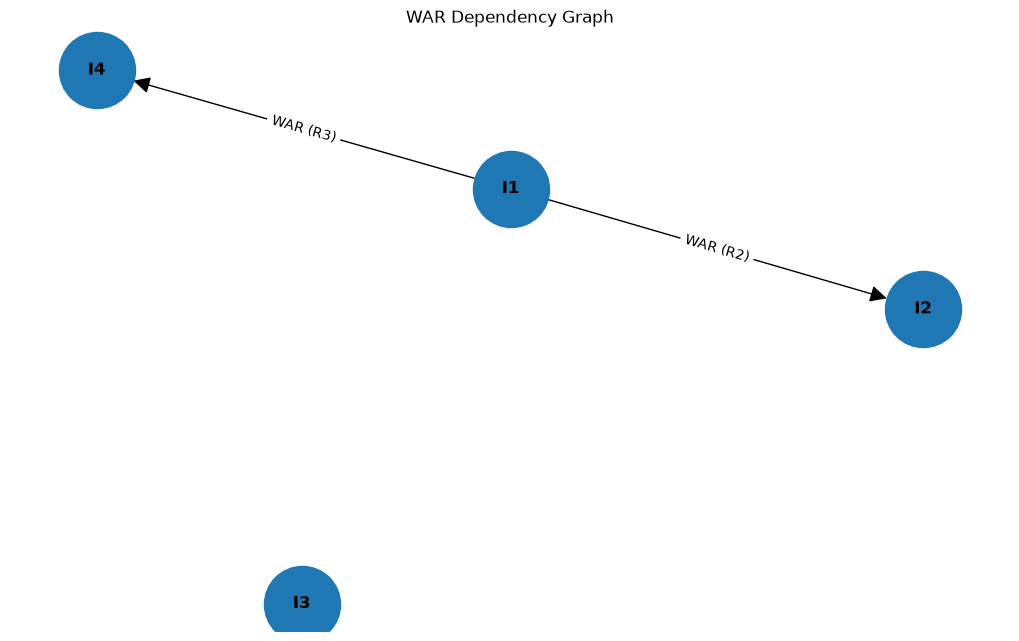

In [5]:
# ==========================================
# WAR DEPENDENCY GRAPH
# ==========================================

# Membuat directed graph
G = nx.DiGraph()

# Menambahkan semua instruksi sebagai node
for i in range(len(instructions)):
    G.add_node(f"I{i + 1}")


# Menambahkan dependency WAR sebagai edge
for dependency in war_dependencies:
    G.add_edge(
        dependency["source"],
        dependency["target"],
        label=f"WAR ({dependency['register']})"
    )


# Menentukan posisi node
pos = nx.spring_layout(G, seed=42)


# Membuat ukuran gambar
plt.figure(figsize=(10, 6))


# Menggambar node dan panah
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    arrows=True,
    arrowsize=25,
    font_size=12,
    font_weight="bold"
)


# Mengambil label dependency
edge_labels = nx.get_edge_attributes(G, "label")


# Menampilkan label pada garis
nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=10
)


plt.title("WAR Dependency Graph")
plt.axis("off")
plt.show()

In [6]:
# ==========================================
# TABEL WAR DEPENDENCY
# ==========================================

print("=== TABEL WAR DEPENDENCY ===")
print()

print(f"{'Source':<10} {'Target':<10} {'Register':<10} {'Type':<10}")
print("-" * 40)

for dependency in war_dependencies:
    print(
        f"{dependency['source']:<10} "
        f"{dependency['target']:<10} "
        f"{dependency['register']:<10} "
        f"{dependency['type']:<10}"
    )

=== TABEL WAR DEPENDENCY ===

Source     Target     Register   Type      
----------------------------------------
I1         I2         R2         WAR       
I1         I4         R3         WAR       


## Kesimpulan

Berdasarkan hasil simulasi, ditemukan dua dependency WAR.

1. Dependency I1 → I2 terjadi karena I1 membaca register R2,
   kemudian I2 menulis register R2.

2. Dependency I1 → I4 terjadi karena I1 membaca register R3,
   kemudian I4 menulis register R3.

Dengan demikian, program berhasil mendeteksi dan memvisualisasikan
dependency Write After Read (WAR) pada instruksi yang diberikan.